# N2H+ Hyperfine Cloud Mapping


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：n2hp_hyperfine_cloud_mapping

**观测 y：** brightness(1, 501, 3, 3)；frequency(1, 501)；hyperfine_velocity_offsets(1, 15)；hyperfine_relative_strengths(1, 15)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 9视线激发温度、光深、速度与线宽图。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 多超精细分量辐射转移生成亮温谱。本地路径为 `solvers.reconstruct→fit_spectrum`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 8, 9, 10（cell编号按文件内从0计）。章节包括：# N2H+ Hyperfine Cloud Mapping；## 1. Problem；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 3×3波束尺度参数成像；9条视线非9独立分辨元，无云参数GT。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Infer excitation temperature, total hyperfine opacity, velocity and Gaussian dispersion maps from real N2H+ spectral lines. Thin-limit temperature/opacity degeneracy and beam overlap limit parameter identifiability.

Active maintainer reconstruction and independently identified scientific comparisons.


Infer excitation temperature, hyperfine opacity, radial velocity and Gaussian
dispersion maps from a real IRAM 30m OphA spectral cube. Hyperfine blending and
saturation couple parameters nonlinearly; excitation and opacity become nearly
nonidentifiable in the thin limit. Nine sky pixels overlap the approximately
26 arcsec telescope beam, so this is beam-scale parameter imaging, not angular
super-resolution or nine independent angular resolution elements.

Save all four float32/float64 **(1,3,3)** arrays to
`output/reconstruction.npz`: `excitation_temperature` [K], `optical_depth`
[dimensionless], `velocity` [km/s], `dispersion` [km/s], axes batch, y, x.
Dispersion is Gaussian sigma, not FWHM; opacity is the sum of component peak
opacities. No map matching, rescaling, masking or alignment is evaluated.
The physical model assumes one component, common excitation and unity beam
filling. The independent original fit is a numerical baseline, not measured
cloud truth. All four maps and forward observation consistency must pass.


## 2. Data

The fixed 3 by 3 OphA patch contains all 501 channels from the original IRAM 30m cube. Brightness is K, frequencies Hz and laboratory component offsets km/s. Nine pixels overlap a roughly 26 arcsecond beam; they are not nine independent angular resolution elements.


The real source is the CDS/VizieR IRAM 30m OphA cube
https://cdsarc.cds.unistra.fr/ftp/J/A+A/472/519/fits/opha_n2h.fit,
catalogue https://cdsarc.cds.unistra.fr/viz-bin/cat/J/A+A/472/519,
Andre et al. (2007), A&A 472, 519. Original FITS shape is (1,501,30,21), with brightness in K;
the bound data preserve `original[0,:,25:28,12:15]`, all 501 channels, exactly
promoting float32 to float64. No baseline refit, smoothing, synthetic injection
or interpolation occurs. The adjacent original 4-by-4 demonstration includes
a thin-limit corner that hit the MPFIT iteration limit with runaway
temperature/opacity; the contiguous 3-by-3 region was bound before extraction,
not selected using cleaned fits. Spatial sampling is 7.50000019203 arcsec.

The original hyperfine method is pyspeckit, repository
https://github.com/pyspeckit/pyspeckit, archived exact commit
`92c69bfdad2980a915a53007b03d8910e10b6bba`, Ginsburg et al. (2022), AJ 163, 291,
DOI 10.3847/1538-3881/ac695a, arXiv 2205.04987v1. The unchanged original MPFIT
model was run on these exact spectra; its measurements are method references,
not physical truth or reused CLASS paper metrics. No latest-HEAD claim is made.
CDS/VizieR supplies scientific-use data with attribution; commercial rights
depend on the original publisher. Molecular constants are legitimate laboratory
calibration, not inferred from hidden maps.

`data/raw_data.npz` contains existing experimental observations and molecular calibration. No simulated observations are generated.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| brightness | (1, 501, 3, 3) | float64 | Measured brightness in K; batch, frequency, y, x; original float32 values promoted without resampling. |
| frequency | (1, 501) | float64 | Channel frequencies in Hz, increasing along channel index. |
| hyperfine_velocity_offsets | (1, 15) | float64 | Laboratory component offsets d in km/s, with the ordering used by the strength vector. |
| hyperfine_relative_strengths | (1, 15) | float64 | Relative strengths w, dimensionless; normalize by their actual sum (0.9999990000000001). |


## 3. Physics

The local uniform-slab model combines fifteen calibrated Gaussian hyperfine opacity profiles with positive-exponent Planck brightness and cosmic-background subtraction. The source component-specific second Doppler factor is preserved. The paper appendix's negative exponent is an identified discrepancy rather than an alternative physical model.


For channel frequency nu[Hz] and parameters p=(Te[K],t0[1],v[km/s],sigma[km/s]),
laboratory offsets d_j[km/s] and strengths w_j[1] determine 15 profiles. Define
c=299792.458 km/s, fc=93173763700 Hz, f_j=fc(1-d_j/c), L_j=f_j(1-d_j/c).
Keep the second component-specific factor: it is the original finite-frequency
Doppler width/shift convention, not a duplicate that can be dropped.


$$
\tau(\nu)=t_0\sum_{j=1}^{15}\frac{w_j}{\sum_lw_l}
\exp\left[-\frac{(\nu+vL_j/c-f_j)^2}{2(\sigma L_j/c)^2}\right],
\quad J(\nu,T)=\frac{h\nu/k}{\exp[h\nu/(kT)]-1},\quad
M(\nu)=[J(\nu,T_e)-J(\nu,2.73)](1-e^{-\tau(\nu)}).
$$


h=6.62607015e-34 J s, k=1.380649e-23 J/K. M is background-subtracted K.
Positive v lowers line frequency; sigma is Gaussian standard deviation.
t0 sums component peak opacities, not integrated or maximum blended opacity.
The actual strength sum 0.9999990000000001 is normalized explicitly.

This uniform-slab model assumes one common excitation and unity beam filling.
It evaluates only supplied channel centers: no spectral padding, interpolation,
periodic boundary, spatial coupling or additional spectrometer convolution.
The radio-axis reference 93176265000 Hz is distinct from fc. T_e=T_b or
t0=0 gives zero emission; high opacity saturates at the source-minus-background
brightness. Thin opacity couples excitation and opacity through their product.
The paper's Appendix D7 negative Planck exponent is inconsistent with Appendix C2,
D6 and the executable model; the positive exponent passes independent thermal
limits and is the disclosed selected convention.


## 4. Method

The selected local bounded TRF least-squares backend retains the original model, initial point, bounds, all-channel noise weighting and independent sightline objective. Original MPFIT and local TRF do not share iteration trajectories; the frozen maximum parameter-error boundaries test their final agreement.


At each sightline estimate noise n as population standard deviation (ddof=0) of observed brightness
at inclusive radio velocity 20..28 km/s, u=c(1-nu/93176265000). Require at
least two channels and positive noise. Fit every supplied channel with residual
r_i=(M_i-D_i)/n, minimizing the sum r_i^2 without spatial prior, continuum,
mask or robust loss. Initial (Te,t0,v,sigma)=(5 K,.5,3 km/s,1 km/s) at every pixel;
bounds Te>=1e-5 K, t0>=0, unrestricted v, sigma>=1e-12 km/s.

The independent original uses bounded MPFIT Levenberg-Marquardt. Local code
uses generic SciPy least_squares(method='trf',jac='3-point',x_scale='jac',
max_nfev=1000,ftol=xtol=gtol=1e-10) on the explicitly local same model,
initialization, bounds and objective. This disclosed backend substitution does
not reproduce MPFIT iteration trajectories. Generic TRF linearizes residuals,
takes scaled bounds-aware trust-region steps, compares actual/predicted cost
decrease and adjusts radius; it stops under cost/step/scaled-gradient criteria
or evaluation limit. A failed success flag raises RuntimeError. Returned chi2 is the
full residual squared norm, not SciPy's half cost. Pixels are independent and
processed row-major, with no neighboring warm start.

Original stopping sensitivity was at most 1.3421499336145399e-5 relative;
the per-map 2e-4 boundary was frozen before extraction. All four map errors
must pass, and maximum reduced chi2=sum r_i^2/(501-4)<=1.3. No original
paper CLASS table is reused as new data. Physical thin-limit degeneracy and
the previously fixed 3-by-3 crop remain disclosed. Frozen forward/noise/loss/
Jacobian/fit fixtures are supplemented by independent thermal limits,
Gaussian opacity integral, redshift sign and noiseless identifiable recovery.


## 5. Results

The active nine-sightline fit retains every parameter map, all spectra/residual groups, full metric table and paired reduced-chi-square bars. Independent original outputs are references; the fixed crop and original failed adjacent thin-limit fit remain disclosed.

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
|---|---|---|---|
| Telescope | IRAM 30m | none | Single-dish spectral mapping of OphA, on-the-fly acquisition. |
| Angular resolution | approximately 26 | arcsec | Telescope beam, not pixel spacing. |
| Spatial sampling | 7.50000019203 | arcsec | Pixel pitch in x and y. |
| Axis orientation | increasing x decreases projected right ascension; increasing y increases declination | none | Original ARC sky-projection array orientation; no periodic spatial boundary. |
| Bound spatial indices | y=25,26,27; x=12,13,14 | zero-based pixel | Contiguous crop of the released CDS cube. |
| Original reference sky coordinate | RA=246.6102288723; Dec=-24.40855924977 | deg | J2000 ARC projection reference. |
| Original spatial reference pixel | x=14.93333352010; y=9.153333173918 | one-based pixel | Reference pixels in the original 21 by 30 grid. |
| Original velocity reference | 2.5 at channel pixel 403.0960083008 | km/s, one-based pixel | FITS velocity-axis calibration. |
| Velocity increment | -0.06284131109715 | km/s | Original consecutive-channel spacing. |
| Radio reference frequency | 93176265000 | Hz | Supplied channel frequencies equal this value times (1-u/c), with u the original radio velocity. |
| Component reference frequency f_c | 93173763700 | Hz | Reference for the 15 molecular component offsets; distinct from the radio-axis reference. |
| Light speed c | 299792.458 | km/s | Doppler conversion convention. |
| Planck constant h | 6.62607015e-34 | J s | Exact SI value. |
| Boltzmann constant k | 1.380649e-23 | J/K | Exact SI value. |
| Background temperature T_b | 2.73 | K | Uniform cosmic microwave background model. |
| Beam filling | 1 | dimensionless | Uniform slab approximation. |
| Spectrometer resolution | 20 | kHz | Published OphA nominal instrumental resolution; use channel samples directly without additional convolution. |
| Noise estimate | population standard deviation of brightness at radio velocities 20 through 28 inclusive, independently at each pixel | K | Data-derived white-noise scale used in chi-square; u=c(1-frequency/93176265000). |
| Baseline convention | supplied background-subtracted brightness; no additional fitted continuum | K | Use every supplied channel in the forward comparison. |
| Spectral boundary | evaluate analytic component profiles only at supplied frequencies | none | No convolution padding or periodic continuation. |


Every fresh reconstruction and comparison here is computed from the loaded real
observations using local src modules. Independent original-code outputs are
labeled references, never physical truth. Previously packaged snapshots are
kept byte-frozen; this execution's runtime and evidence are captured privately.
Display normalization affects figure contrast only, not quantitative arrays.

### Fresh full nine-sightline reconstruction


### All four original/fresh/difference parameter-map rows


### All three observed/original/fresh spectra and noise-normalized residual groups


### Four-map errors, full metric table and paired nine-pixel reduced-chi-square bars


In [1]:
from pathlib import Path
import sys, time, json, importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks': root=root.parent
if not (root/'src').exists(): raise RuntimeError('Execute from task root or notebooks directory')
sys.path.insert(0,str(root))
from src.preprocessing import load_observations,estimate_noise
from src.physics_model import predict_cube, C_KMS, REST_FREQUENCY
from src.solvers import reconstruct,OUTPUT_KEYS
from src.visualization import compare_maps
cube,frequency=load_observations(root/'data/raw_data.npz')
print('Measured brightness cube:',cube.shape,'K; no cached reconstruction mode')

with np.load(root/'data/raw_data.npz',allow_pickle=False) as visible:
    print('Visible acquisition arrays (batch first on disk):')
    for key in visible.files: print(key,visible[key].shape,str(visible[key].dtype))


Measured brightness cube: (501, 3, 3) K; no cached reconstruction mode
Visible acquisition arrays (batch first on disk):
brightness (1, 501, 3, 3) float64
frequency (1, 501) float64
hyperfine_velocity_offsets (1, 15) float64
hyperfine_relative_strengths (1, 15) float64


In [2]:
start=time.perf_counter()
fresh,chi_square=reconstruct(cube,frequency)
runtime=time.perf_counter()-start
parameters=np.stack([fresh[k][0] for k in OUTPUT_KEYS])
model=predict_cube(frequency,parameters)
(root/'output').mkdir(exist_ok=True)
np.savez_compressed(root/'output/reconstruction.npz',**fresh)
print(f'Fresh CPU reconstruction: {runtime:.6f} seconds')

Fresh CPU reconstruction: 0.155965 seconds


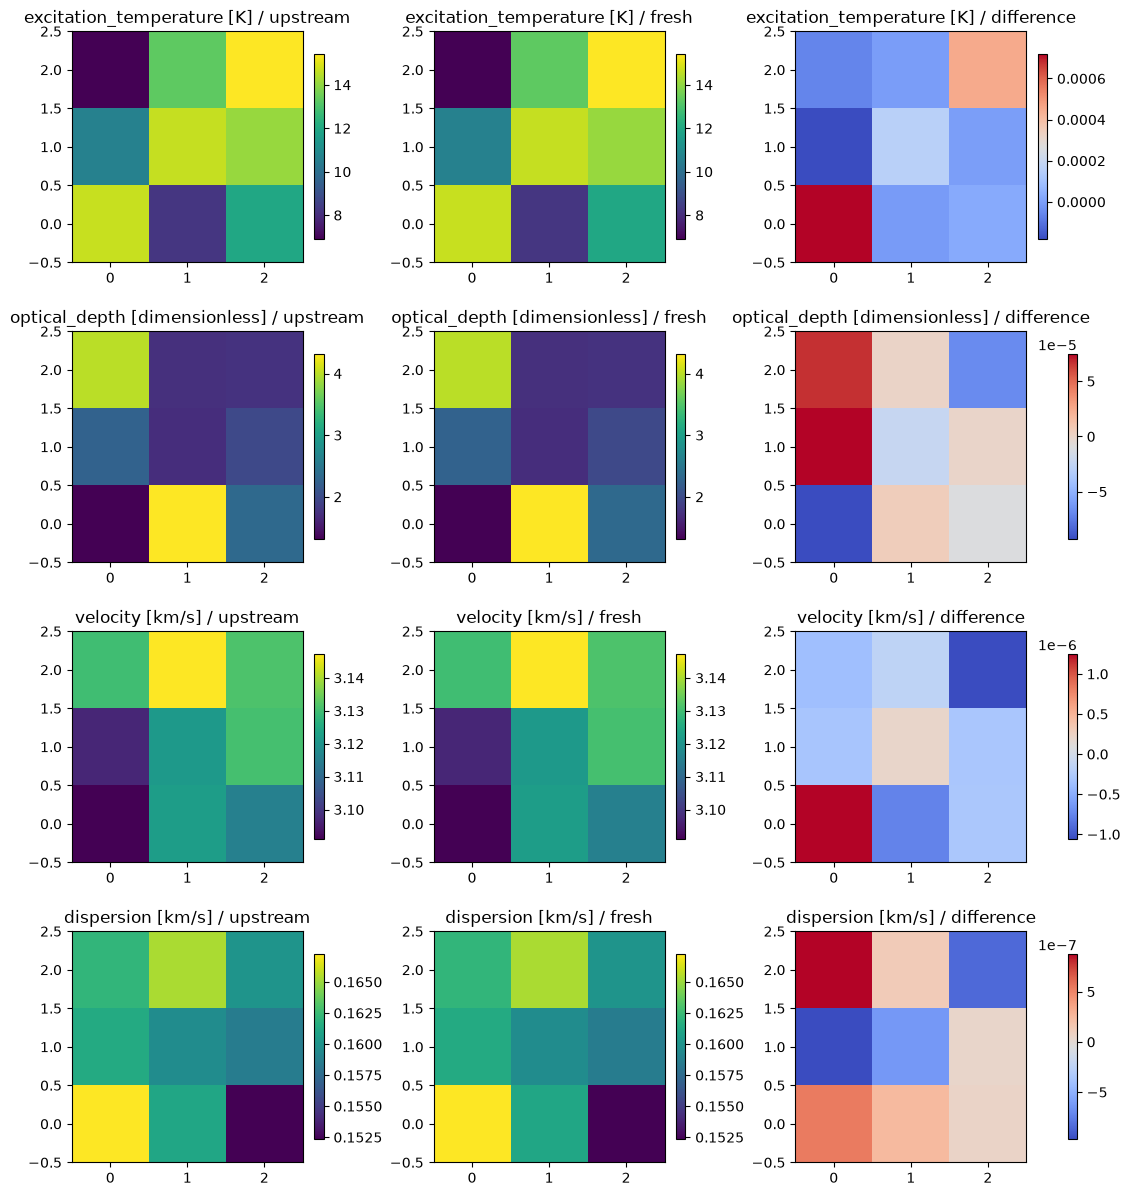

In [3]:
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as archive:
    upstream_parameters=archive['parameters'][0]
    upstream_model=archive['model'][0]
    upstream_chi=archive['chi_square']
upstream={k:upstream_parameters[i][None] for i,k in enumerate(OUTPUT_KEYS)}
fig=compare_maps(fresh,upstream)
plt.show()

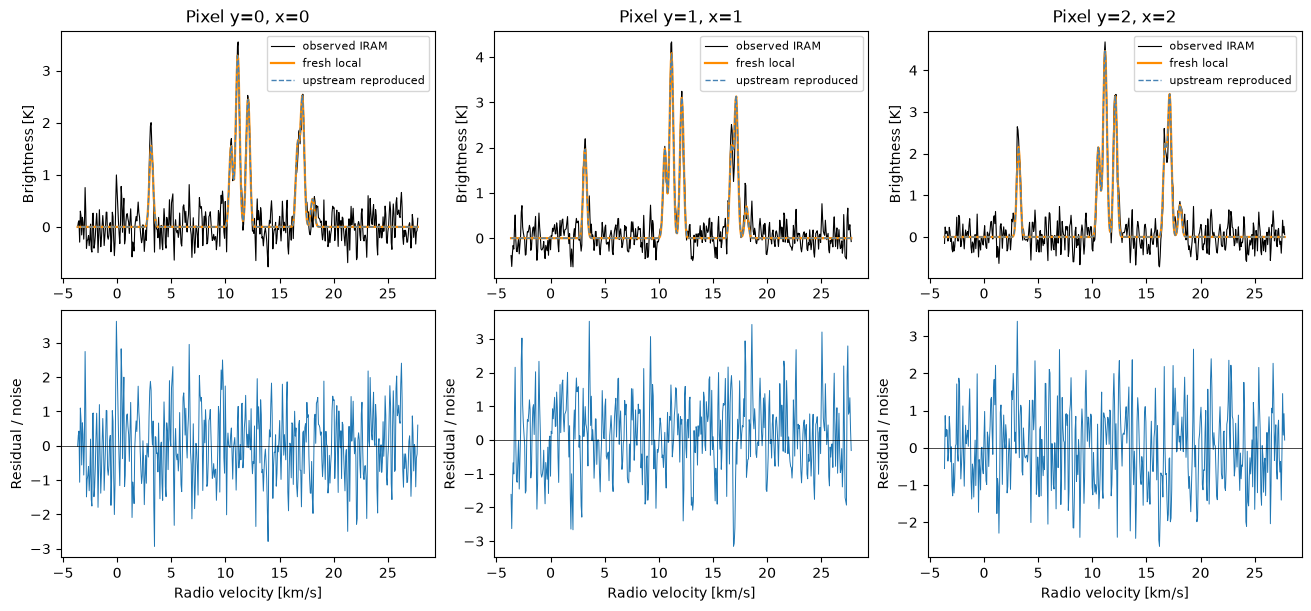

In [4]:
velocity=C_KMS*(1-frequency/REST_FREQUENCY)
noise=estimate_noise(cube,frequency)
fig,axes=plt.subplots(2,3,figsize=(13,6),constrained_layout=True)
for column,(y,x) in enumerate([(0,0),(1,1),(2,2)]):
    axes[0,column].plot(velocity,cube[:,y,x],color='black',lw=.8,label='observed IRAM')
    axes[0,column].plot(velocity,model[:,y,x],color='darkorange',lw=1.6,label='fresh local')
    axes[0,column].plot(velocity,upstream_model[:,y,x],'--',color='steelblue',lw=1,label='upstream reproduced')
    axes[0,column].set_title(f'Pixel y={y}, x={x}')
    axes[0,column].set_ylabel('Brightness [K]');axes[0,column].legend(fontsize=8)
    axes[1,column].plot(velocity,(cube[:,y,x]-model[:,y,x])/noise[y,x],lw=.7)
    axes[1,column].axhline(0,color='black',lw=.5)
    axes[1,column].set_ylabel('Residual / noise');axes[1,column].set_xlabel('Radio velocity [km/s]')
plt.show()

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "excitation_temperature_relative_max": 4.8828702486725936e-05,
    "optical_depth_relative_max": 7.101986760430604e-05,
    "velocity_relative_max": 4.02668660382813e-07,
    "dispersion_relative_max": 6.010691065585748e-06,
    "maximum_reduced_chi_square": 1.2160321401279806
  },
  "thresholds": {
    "excitation_temperature_relative_max": {
      "comparison": "<=",
      "boundary": 0.0002
    },
    "optical_depth_relative_max": {
      "comparison": "<=",
      "boundary": 0.0002
    },
    "velocity_relative_max": {
      "comparison": "<=",
      "boundary": 0.0002
    },
    "dispersion_relative_max": {
      "comparison": "<=",
      "boundary": 0.0002
    },
    "maximum_reduced_chi_square": {
      "comparison": "<=",
      "boundary": 1.3
    }
  },
  "errors": []
}
method                 maximum reduced chi-square
upstream reproduced    1.2160321401642158
fresh local            1.2160321401279806
quantity         

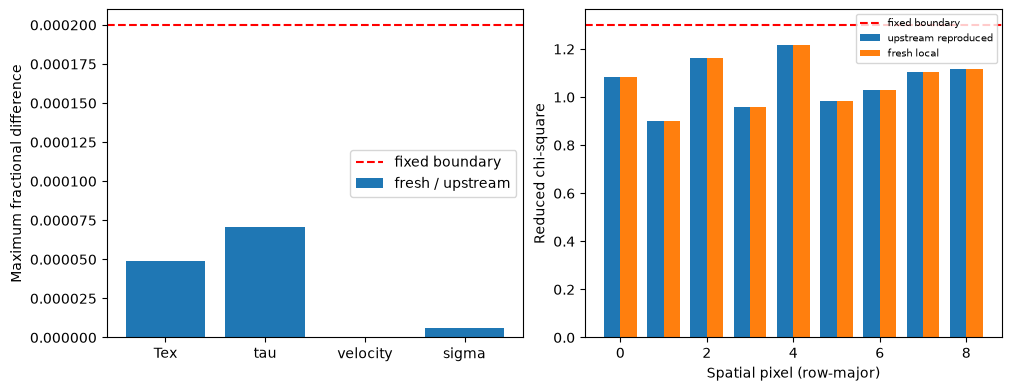

In [5]:
spec=importlib.util.spec_from_file_location('review_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(root/'output/reconstruction.npz')
assert code==0,report
print(json.dumps(report,indent=2))
print('method                 maximum reduced chi-square')
print('upstream reproduced   ',float(upstream_chi.max()/497))
print('fresh local           ',float(chi_square.max()/497))
print('quantity                    max fractional error')
for key in OUTPUT_KEYS:
    print(f'{key:28s}{np.max(np.abs((fresh[key]-upstream[key])/upstream[key])):.12g}')
fig,axes=plt.subplots(1,2,figsize=(10,3.8),constrained_layout=True)
x=np.arange(4)
axes[0].bar(x,[report['metrics'][k+'_relative_max'] for k in OUTPUT_KEYS],label='fresh / upstream')
axes[0].axhline(.0002,color='red',ls='--',label='fixed boundary')
axes[0].set_xticks(x,['Tex','tau','velocity','sigma']);axes[0].set_ylabel('Maximum fractional difference');axes[0].legend()
x=np.arange(9);w=.38
axes[1].bar(x-w/2,upstream_chi.ravel()/497,w,label='upstream reproduced')
axes[1].bar(x+w/2,chi_square.ravel()/497,w,label='fresh local')
axes[1].axhline(1.3,color='red',ls='--',label='fixed boundary')
axes[1].set_xlabel('Spatial pixel (row-major)');axes[1].set_ylabel('Reduced chi-square');axes[1].legend(fontsize=7)
plt.show()

## 6. Conclusion

The comparisons support numerical reproduction of the selected weighted single-component model. They establish neither uniquely known cloud properties nor spatial super-resolution; beam filling, common excitation, white-noise weighting and thin-opacity coupling remain limiting assumptions.


The actively computed four-map local result passes every prespecified maximum
relative parameter-error boundary and the observation reduced chi-square gate.
Paired nine-pixel bars remain near unit reduced chi-square (original maximum
1.2160321401642157), and measured spectral/residual groups retain all hyperfine
components. This supports numerical reproduction of the declared single-component
model and weighted objective with the disclosed generic optimizer substitution.

It does not establish uniquely known cloud parameters or MPFIT step-for-step
parity. One excitation component, unity beam filling, constant background, supplied
baseline and white-noise weighting are approximations; adjacent pixels share
the 26 arcsec beam. Thin opacity makes excitation/opacity nearly degenerate and
caused excluded neighboring example fits to run away. Conclusions apply to the
bound 3-by-3 patch and this transfer model; no spatial super-resolution or full
upstream 4-by-4 demonstration is claimed. The positive Planck exponent and original
component Doppler conventions were independently checked and kept explicit.

Source provenance, independent original-run evidence, tests, precise parameter conventions and preserved copyright/license records: `test/validation.md`; executable mathematical and interface detail: `plan/approach.md` and `plan/design.md`.
